In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from churn.config import RAW_DIR
from churn.eda import (
    analyze_churn_by_feature,
    add_bin_features_cut,
    add_bin_features_qcut,
)


In [9]:
train = pd.read_csv(RAW_DIR / "train.csv")

In [7]:
train.head()

,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,...,Yes,Yes,No,No,One year,Yes,Mailed check,60.10,1653.85,No
1,1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,...,No,Yes,Yes,No,Two year,No,Credit card (automatic),69.50,3778.20,No
2,2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.40,5841.35,No
3,3,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.70,70.70,Yes
4,4,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.45,70.45,Yes


In [10]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 594194 entries, 0 to 594193
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   id                594194 non-null  int64  
 1   gender            594194 non-null  str    
 2   SeniorCitizen     594194 non-null  int64  
 3   Partner           594194 non-null  str    
 4   Dependents        594194 non-null  str    
 5   tenure            594194 non-null  int64  
 6   PhoneService      594194 non-null  str    
 7   MultipleLines     594194 non-null  str    
 8   InternetService   594194 non-null  str    
 9   OnlineSecurity    594194 non-null  str    
 10  OnlineBackup      594194 non-null  str    
 11  DeviceProtection  594194 non-null  str    
 12  TechSupport       594194 non-null  str    
 13  StreamingTV       594194 non-null  str    
 14  StreamingMovies   594194 non-null  str    
 15  Contract          594194 non-null  str    
 16  PaperlessBilling  594194 non-nu

In [11]:
train.describe()

,id,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,594194.000000,594194.000000,594194.000000,594194.000000,594194.000000
mean,297096.500000,0.114102,36.577258,65.866223,2494.377057
std,171529.177263,0.317936,25.061922,31.067444,2353.916710
min,0.000000,0.000000,1.000000,18.250000,18.800000
25%,148548.250000,0.000000,12.000000,29.900000,639.650000
50%,297096.500000,0.000000,35.000000,74.100000,1433.650000
75%,445644.750000,0.000000,62.000000,90.800000,4263.800000
max,594193.000000,1.000000,72.000000,118.750000,8684.800000


In [12]:
# 总群体流失概率
(train["Churn"] == "Yes").mean()

np.float64(0.225207592133209)

In [13]:
train["SeniorCitizen"] = train["SeniorCitizen"].map({
    0:"非老年",
    1:"老年"
})

In [14]:
exclude_items = ["id", "Churn"]
feature_items = [c for c in train.columns if c not in exclude_items]
features_in_str  = train[feature_items].select_dtypes(include = ["str"]).columns.tolist()
features_in_num = train[feature_items].select_dtypes(include = ["number"]).columns.tolist()

In [15]:
# 对数值字段做分箱处理
name_bin = []
name_bin.append(add_bin_features_cut(train, features_in_num[0], 6)[1])
name_bin.append(add_bin_features_qcut(train, features_in_num[1], 5)[1])
name_bin.append(add_bin_features_qcut(train, features_in_num[2], 10)[1])
for item in name_bin:
    features_in_str.append(item)
    display(train[item].value_counts().sort_index())
    print("==================================================================")

tenure_bin
0 ~ 6       86374
6 ~ 12      66272
12 ~ 18     46948
18 ~ 24     39076
24 ~ 30     35198
30 ~ 36     30977
36 ~ 42     29484
42 ~ 48     32329
48 ~ 54     36451
54 ~ 60     32978
60 ~ 66     42276
66 ~ 72    115831
Name: count, dtype: int64

MonthlyCharges_qcut
(18.249, 24.4]    118885
(24.4, 61.25]     118800
(61.25, 80.4]     118945
(80.4, 95.0]      118963
(95.0, 118.75]    118601
Name: count, dtype: int64

TotalCharges_qcut
(18.799, 176.3]       59431
(176.3, 515.25]       59410
(515.25, 765.35]      59446
(765.35, 1090.95]     59399
(1090.95, 1433.65]    59416
(1433.65, 2156.25]    59441
(2156.25, 3462.1]     59401
(3462.1, 4908.25]     59439
(4908.25, 6312.9]     59418
(6312.9, 8684.8]      59393
Name: count, dtype: int64

特征 gender 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
gender,,,,,
Female,298738,68123,0.2280,0.5028,1.0126
Male,295456,65694,0.2223,0.4972,0.9873


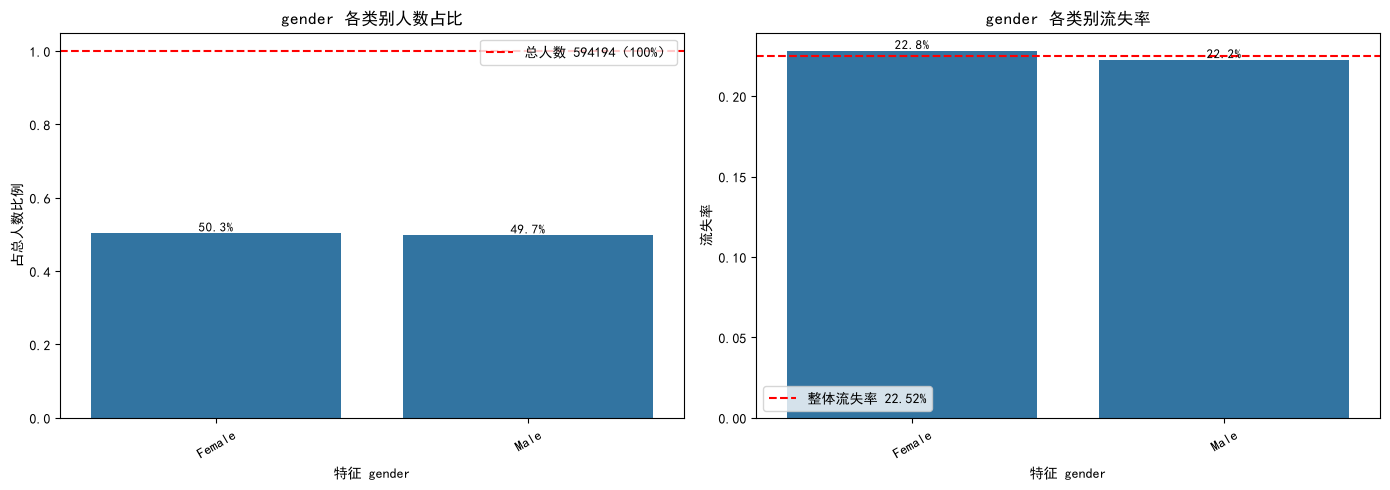

特征 SeniorCitizen 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
SeniorCitizen,,,,,
老年,67799,33921,0.5003,0.1141,2.2216
非老年,526395,99896,0.1898,0.8859,0.8427


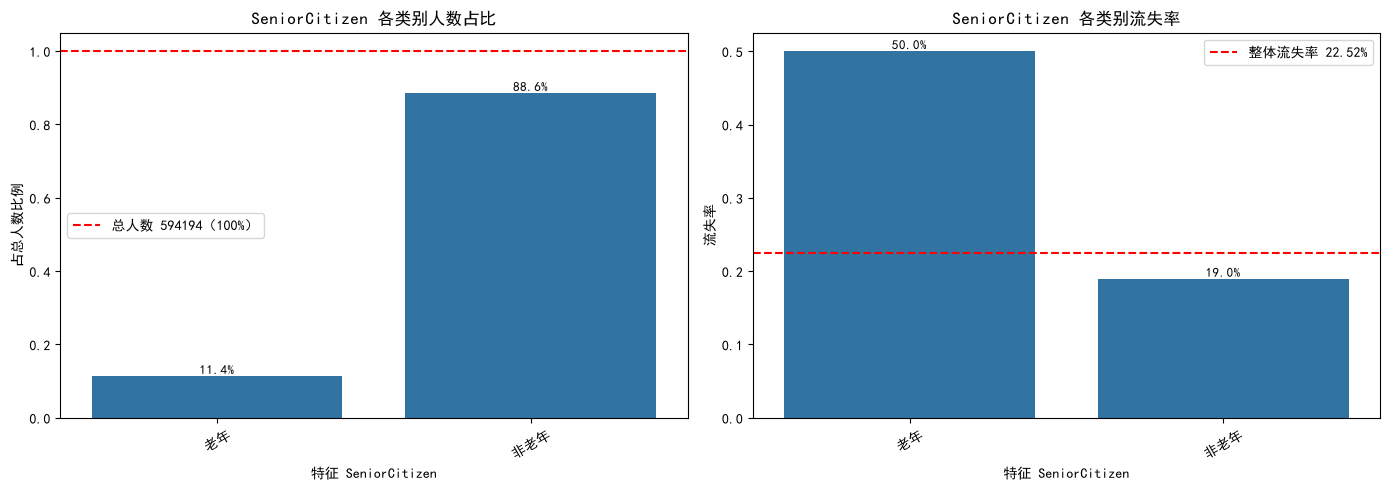

特征 Partner 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
Partner,,,,,
No,284640,92400,0.3246,0.479,1.4414
Yes,309554,41417,0.1338,0.521,0.5941


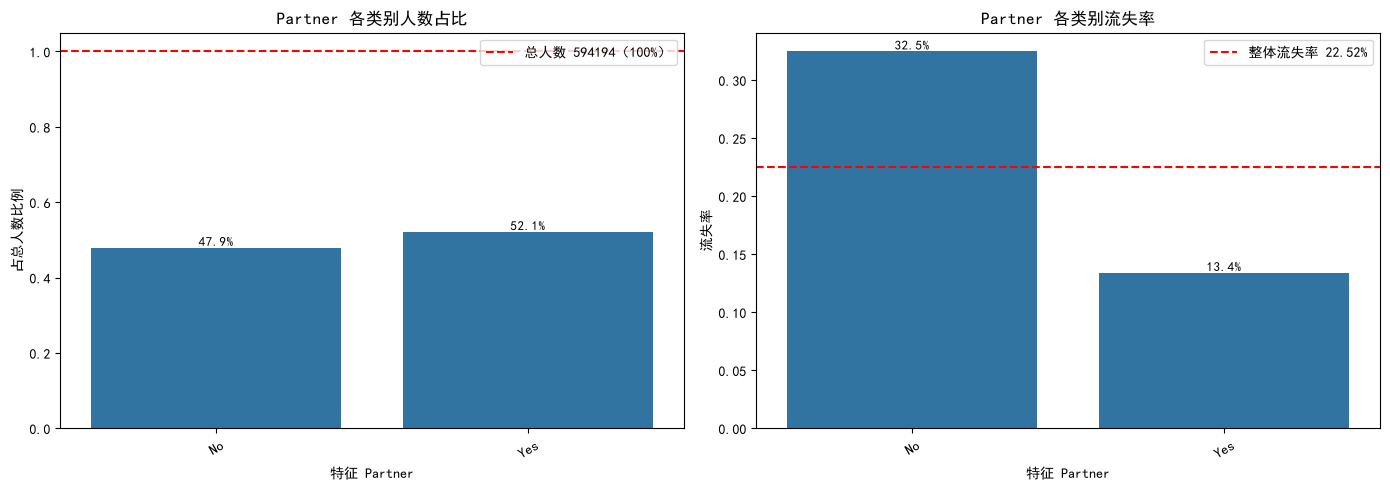

特征 Dependents 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
Dependents,,,,,
No,414362,120726,0.2914,0.6974,1.2937
Yes,179832,13091,0.0728,0.3026,0.3232


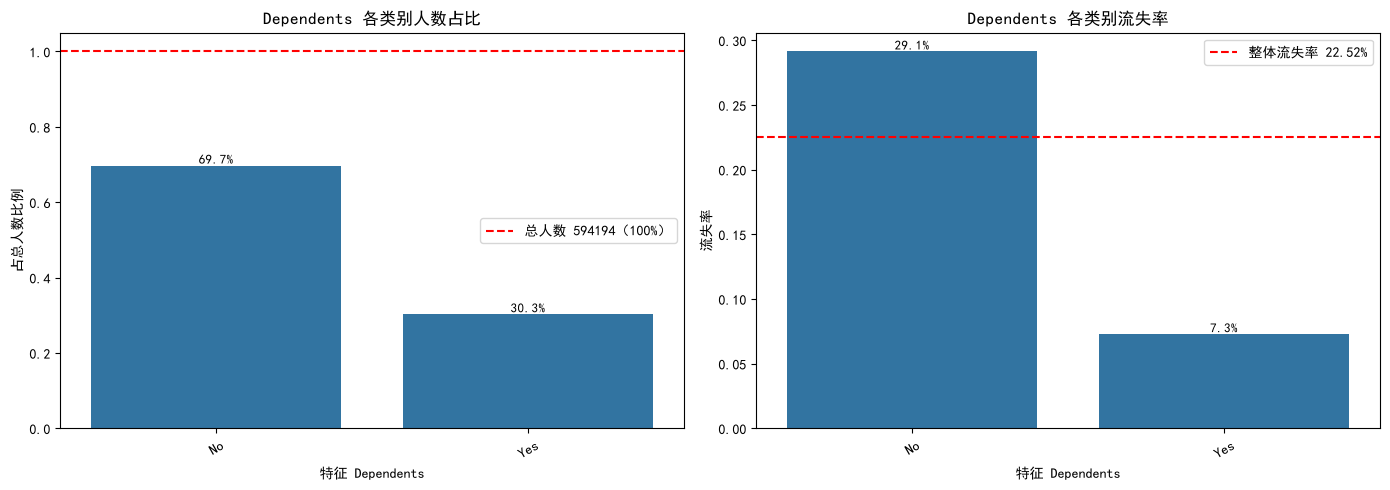

特征 PhoneService 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
PhoneService,,,,,
Yes,557893,127713,0.2289,0.9389,1.0165
No,36301,6104,0.1681,0.0611,0.7466


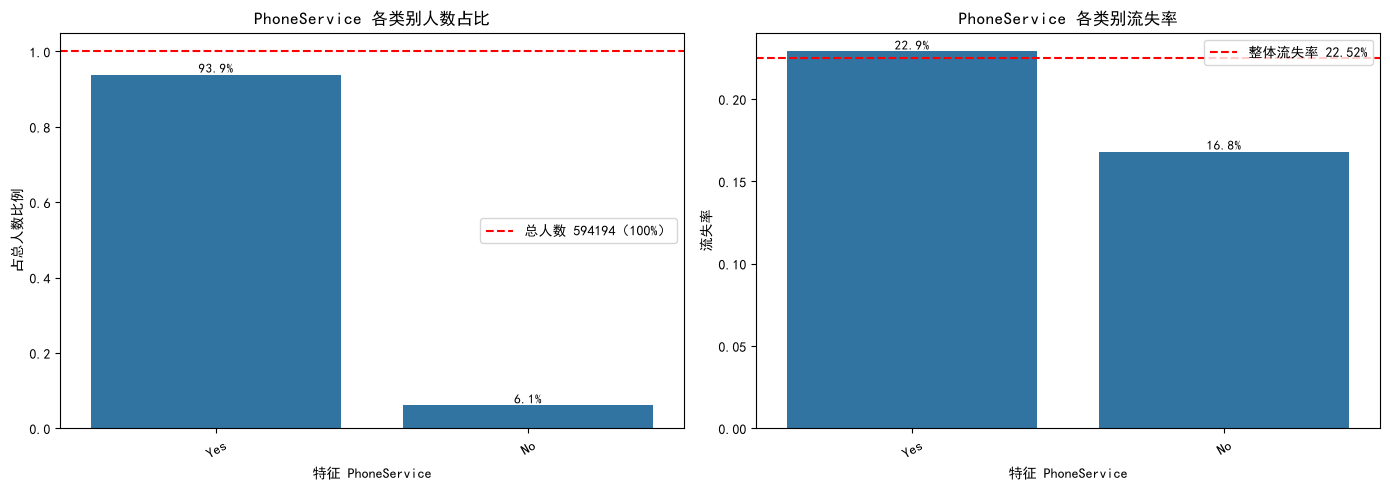

特征 MultipleLines 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
MultipleLines,,,,,
Yes,274509,76046,0.2770,0.4620,1.2301
No,283384,51667,0.1823,0.4769,0.8096
No phone service,36301,6104,0.1681,0.0611,0.7466


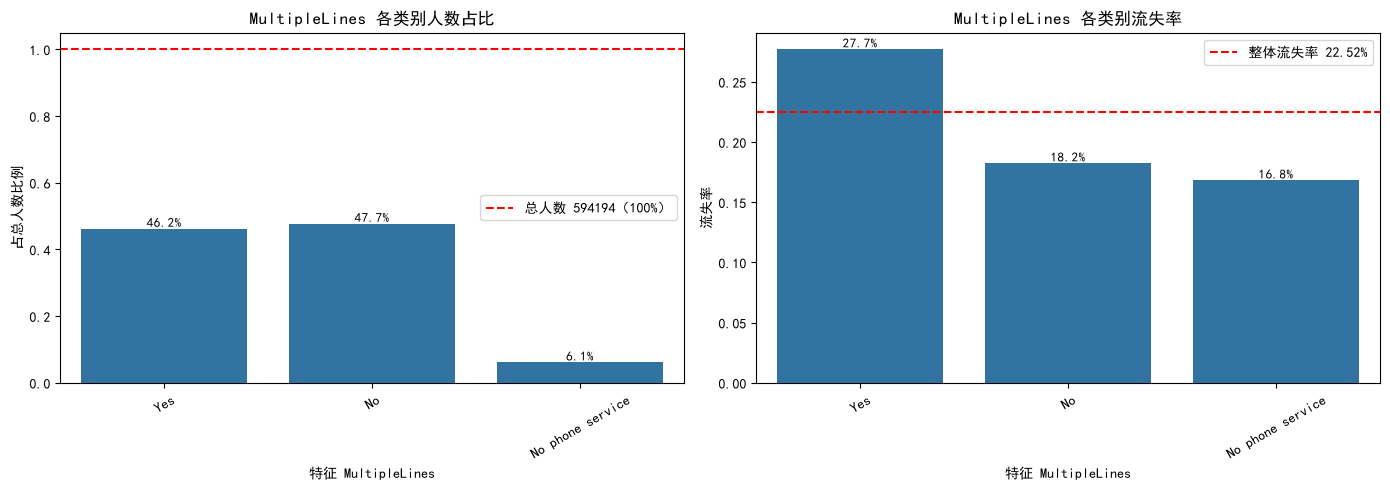

特征 InternetService 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
InternetService,,,,,
Fiber optic,272386,113140,0.4154,0.4584,1.8444
DSL,181081,18663,0.1031,0.3048,0.4576
No,140727,2014,0.0143,0.2368,0.0635


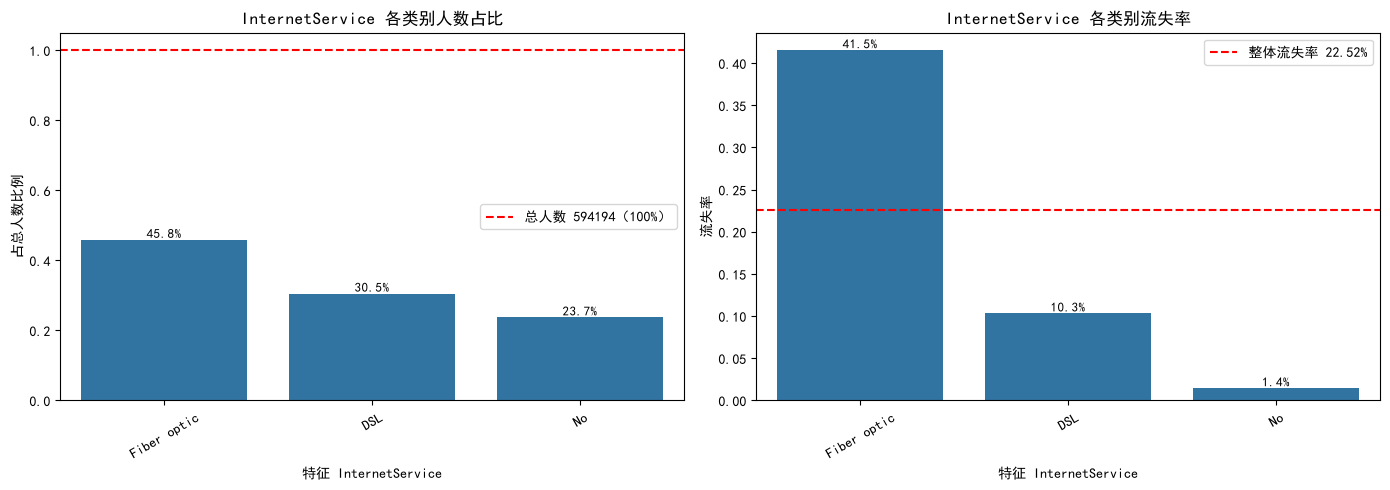

特征 OnlineSecurity 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
OnlineSecurity,,,,,
No,289474,117565,0.4061,0.4872,1.8034
Yes,163993,14238,0.0868,0.2760,0.3855
No internet service,140727,2014,0.0143,0.2368,0.0635


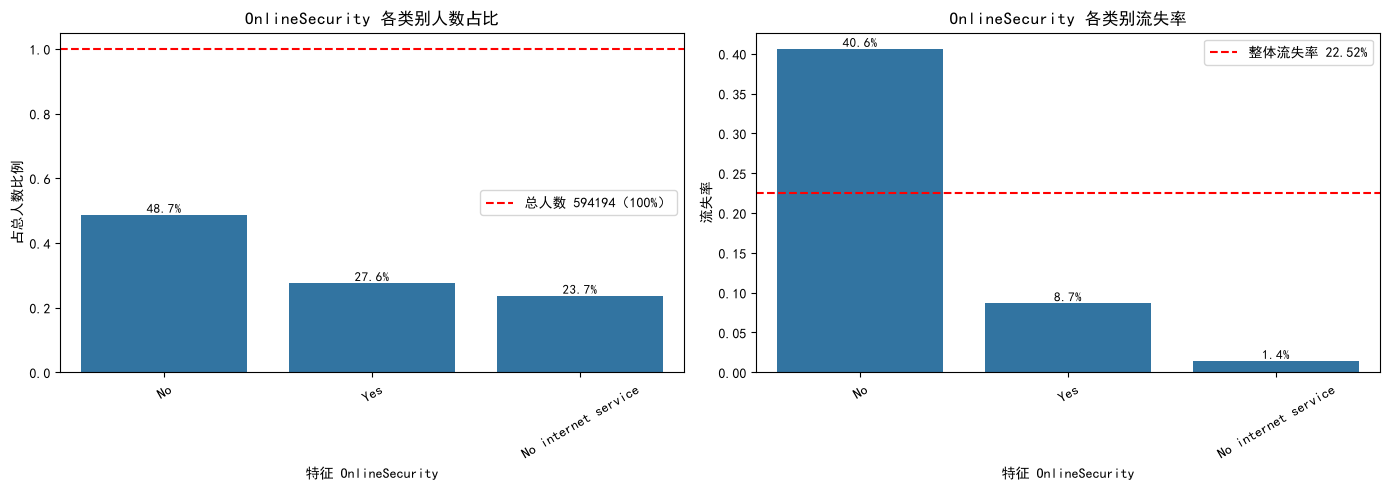

特征 OnlineBackup 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
OnlineBackup,,,,,
No,250083,97789,0.3910,0.4209,1.7363
Yes,203384,34014,0.1672,0.3423,0.7426
No internet service,140727,2014,0.0143,0.2368,0.0635


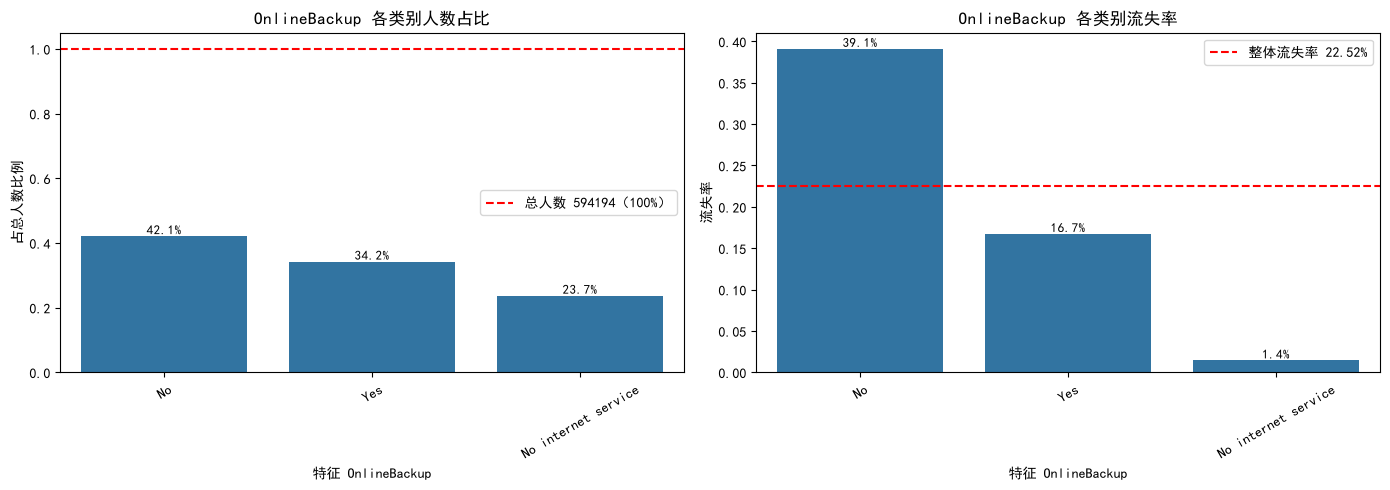

特征 DeviceProtection 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
DeviceProtection,,,,,
No,247377,94159,0.3806,0.4163,1.6901
Yes,206090,37644,0.1827,0.3468,0.8111
No internet service,140727,2014,0.0143,0.2368,0.0635


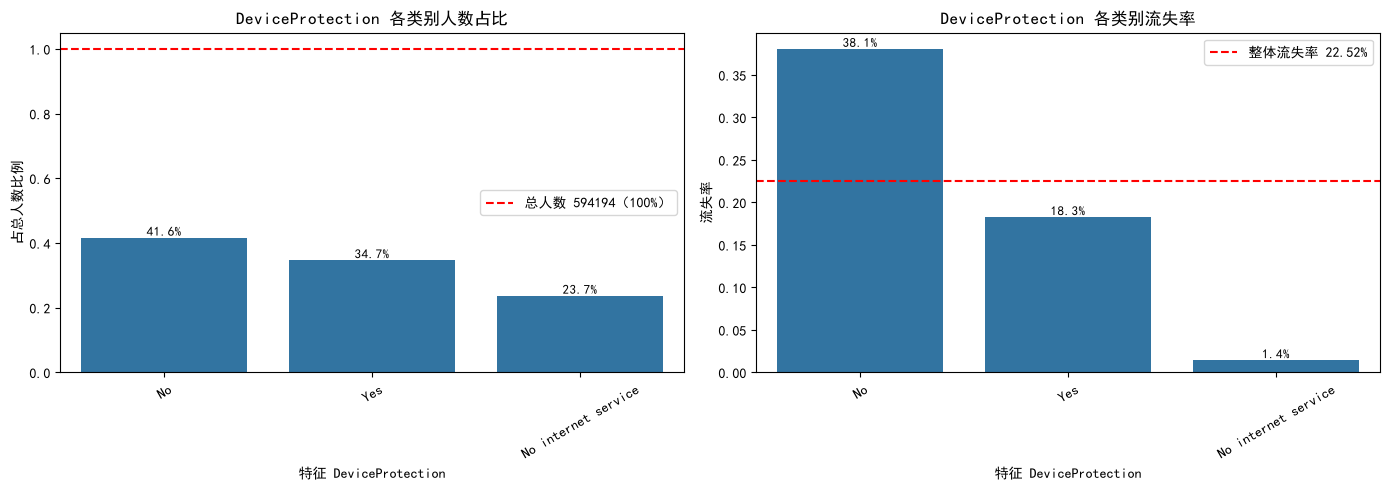

特征 TechSupport 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
TechSupport,,,,,
No,288571,115896,0.4016,0.4857,1.7833
Yes,164896,15907,0.0965,0.2775,0.4283
No internet service,140727,2014,0.0143,0.2368,0.0635


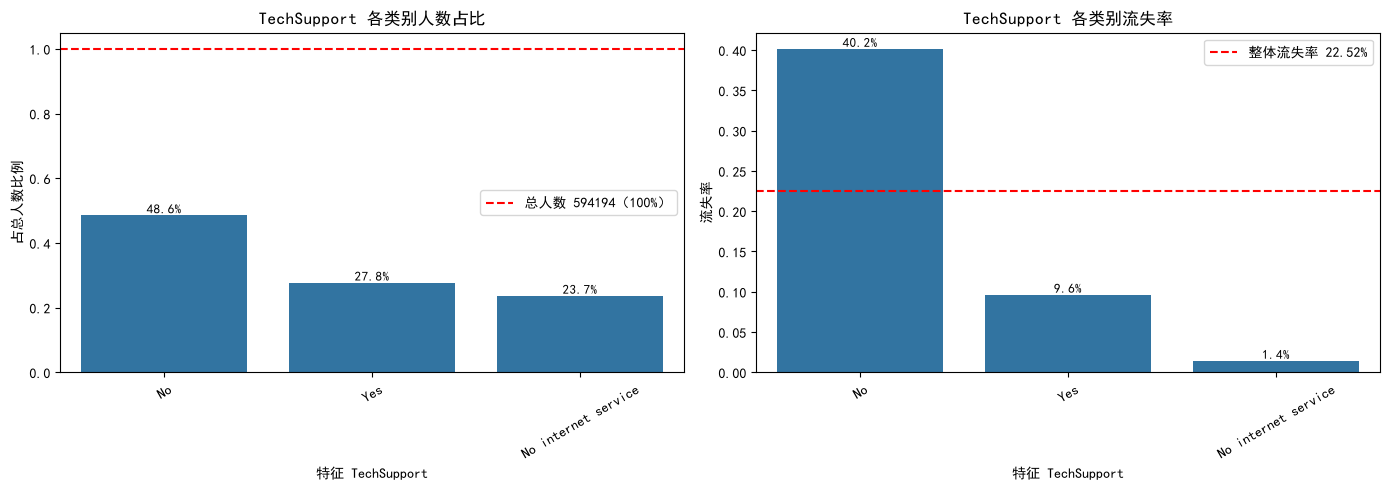

特征 StreamingTV 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
StreamingTV,,,,,
No,213166,63399,0.2974,0.3587,1.3206
Yes,240301,68404,0.2847,0.4044,1.2640
No internet service,140727,2014,0.0143,0.2368,0.0635


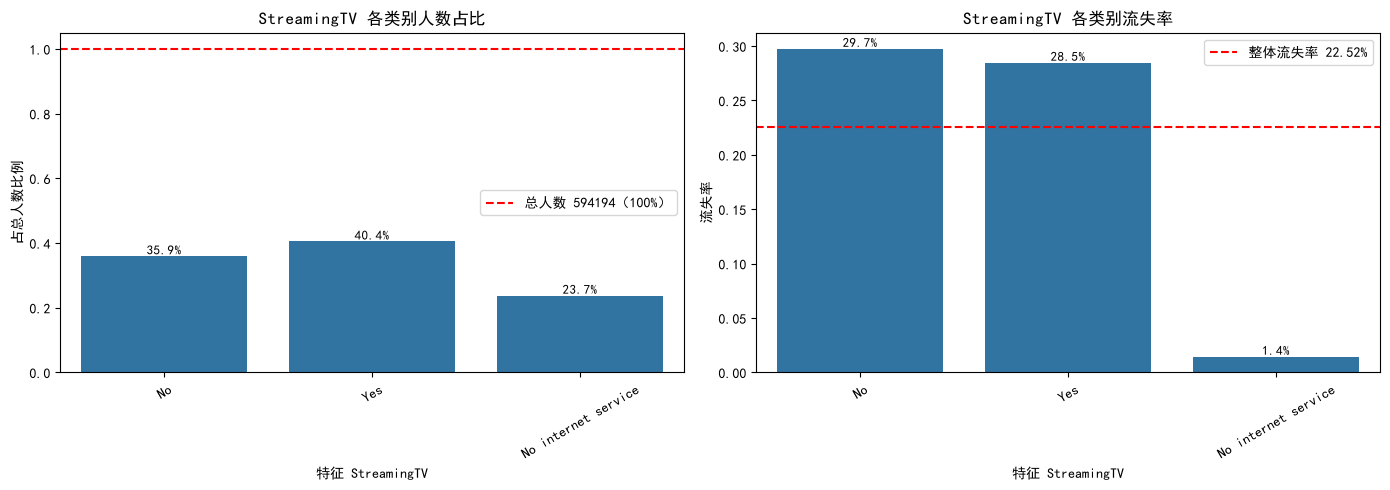

特征 StreamingMovies 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
StreamingMovies,,,,,
No,212032,63461,0.2993,0.3568,1.3290
Yes,241435,68342,0.2831,0.4063,1.2569
No internet service,140727,2014,0.0143,0.2368,0.0635


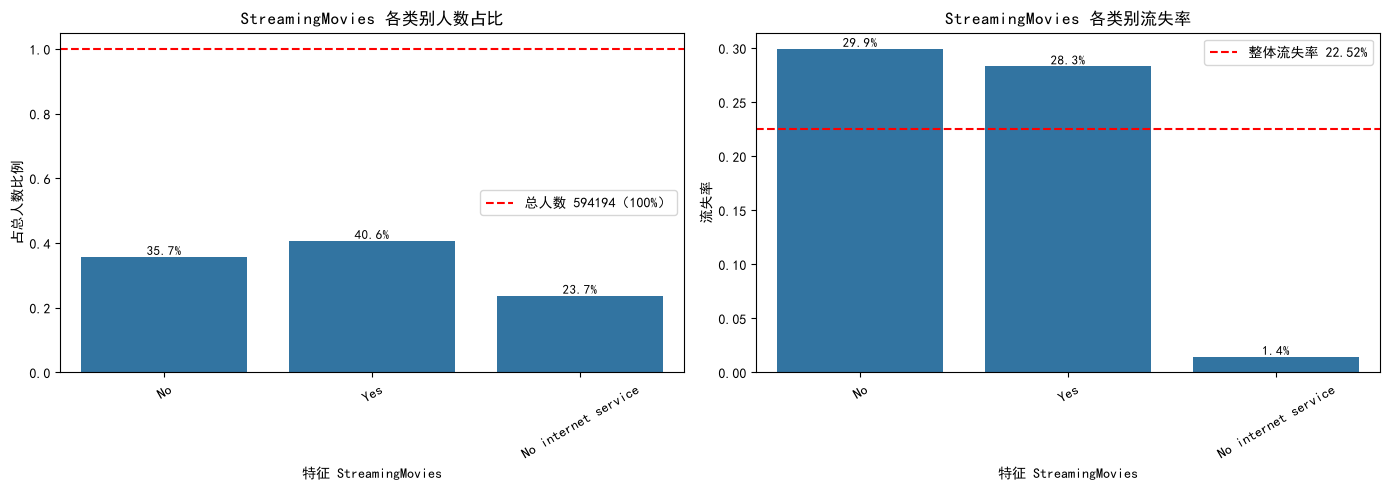

特征 Contract 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
Contract,,,,,
Month-to-month,298918,125708,0.4205,0.5031,1.8674
One year,108333,6243,0.0576,0.1823,0.2559
Two year,186943,1866,0.0100,0.3146,0.0443


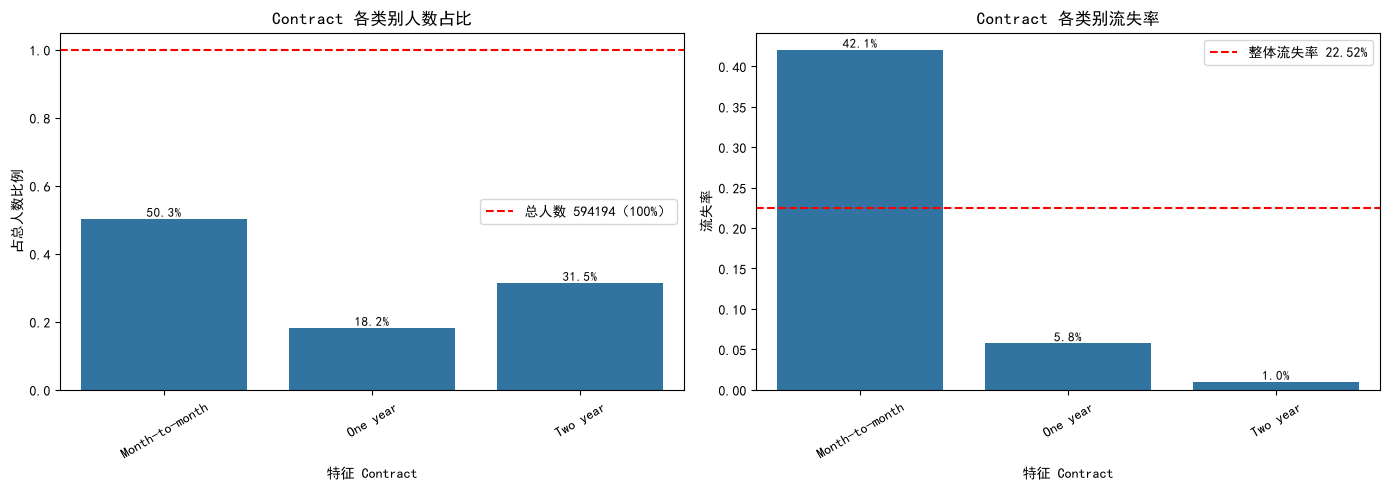

特征 PaperlessBilling 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
PaperlessBilling,,,,,
Yes,365579,116761,0.3194,0.6153,1.4182
No,228615,17056,0.0746,0.3847,0.3313


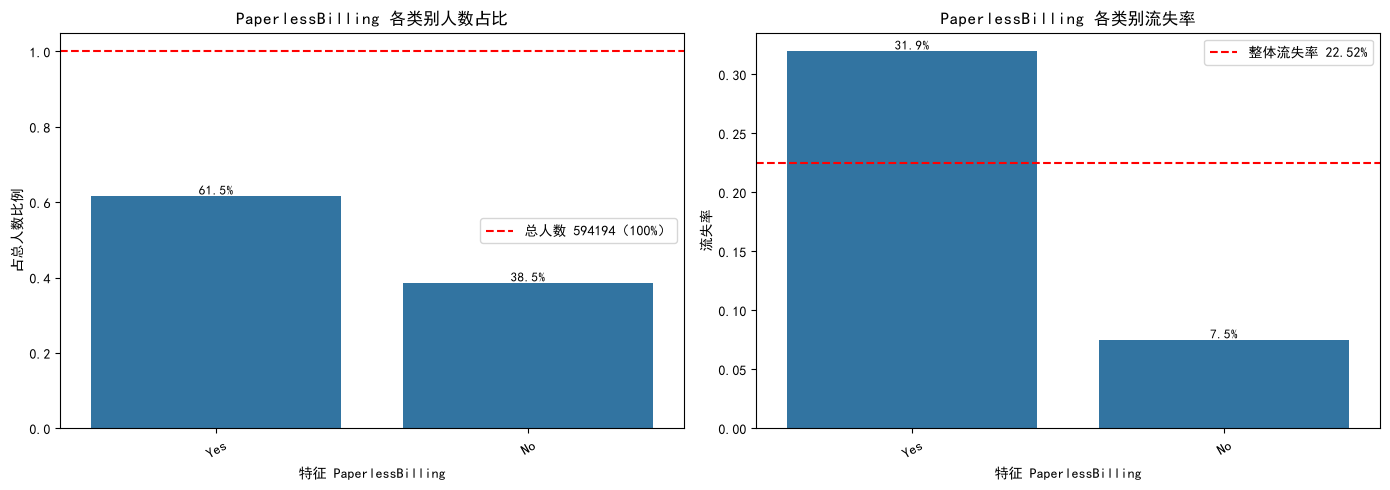

特征 PaymentMethod 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
PaymentMethod,,,,,
Electronic check,215372,105328,0.4891,0.3625,2.1716
Mailed check,123757,9863,0.0797,0.2083,0.3539
Bank transfer (automatic),121360,9356,0.0771,0.2042,0.3423
Credit card (automatic),133705,9270,0.0693,0.2250,0.3079


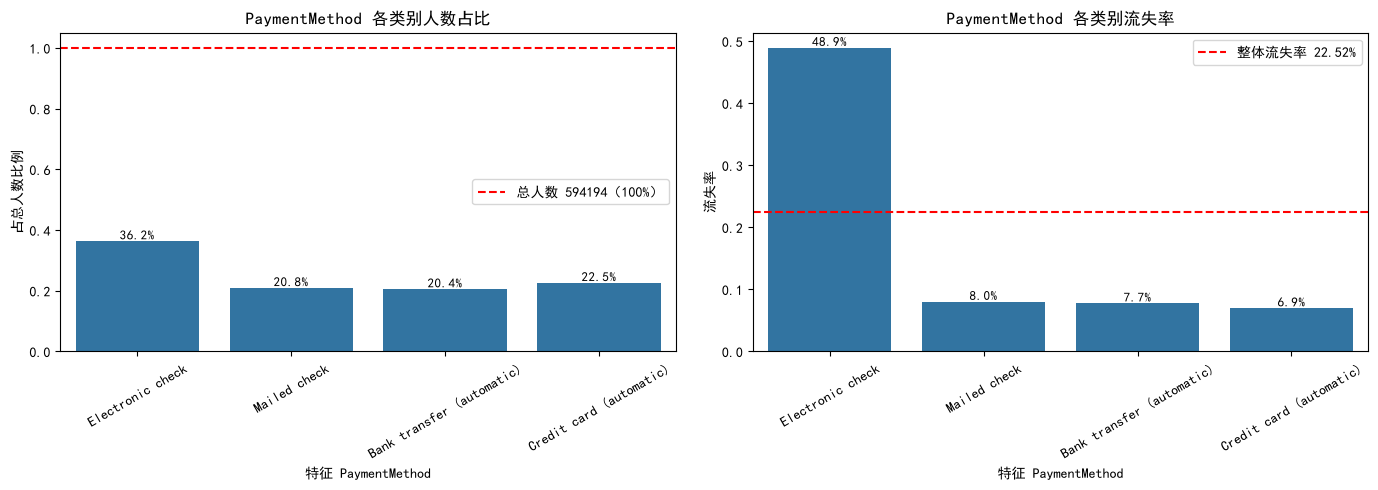

特征 tenure_bin 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
tenure_bin,,,,,
0 ~ 6,86374,46946,0.5435,0.1454,2.4134
6 ~ 12,66272,28453,0.4293,0.1115,1.9064
12 ~ 18,46948,15937,0.3395,0.0790,1.5073
18 ~ 24,39076,8647,0.2213,0.0658,0.9826
24 ~ 30,35198,7674,0.2180,0.0592,0.9681
30 ~ 36,30977,6013,0.1941,0.0521,0.8619
36 ~ 42,29484,4905,0.1664,0.0496,0.7387
42 ~ 48,32329,3250,0.1005,0.0544,0.4464
48 ~ 54,36451,3502,0.0961,0.0613,0.4266


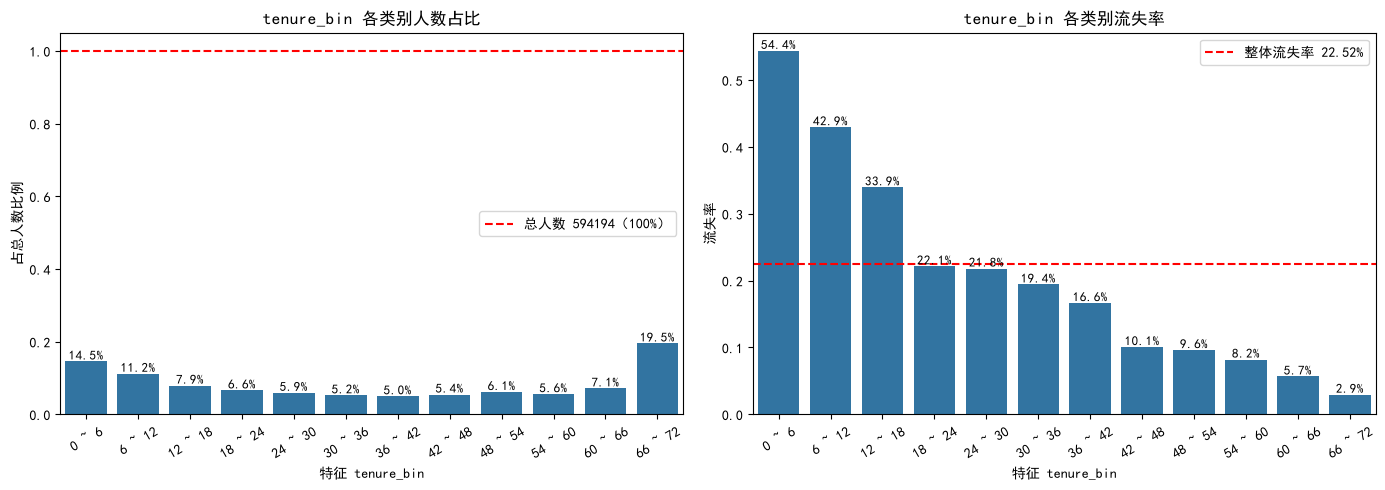

特征 MonthlyCharges_qcut 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
MonthlyCharges_qcut,,,,,
"(80.4, 95.0]",118963,43321,0.3642,0.2002,1.6170
"(61.25, 80.4]",118945,36925,0.3104,0.2002,1.3785
"(95.0, 118.75]",118601,35192,0.2967,0.1996,1.3176
"(24.4, 61.25]",118800,16331,0.1375,0.1999,0.6104
"(18.249, 24.4]",118885,2048,0.0172,0.2001,0.0765


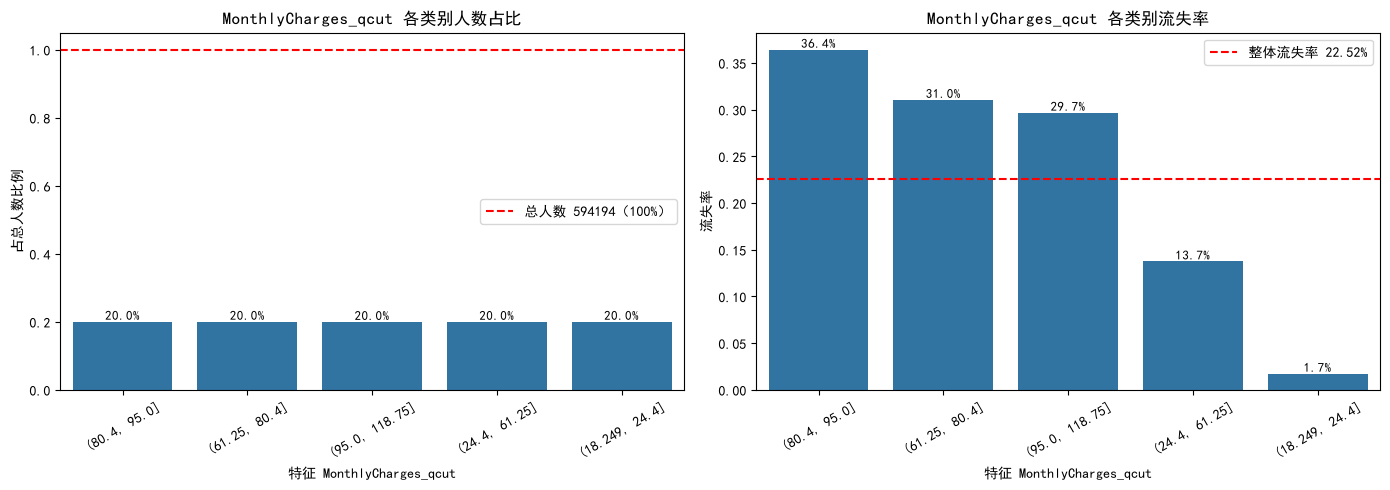

特征 TotalCharges_qcut 与流失的数据统计（整体流失率 22.52%）:


,总人数,流失人数,流失率,占比,流失相对倍数
TotalCharges_qcut,,,,,
"(18.799, 176.3]",59431,27832,0.4683,0.1,2.0794
"(176.3, 515.25]",59410,19300,0.3249,0.1,1.4425
"(515.25, 765.35]",59446,16600,0.2792,0.1,1.2399
"(2156.25, 3462.1]",59401,15562,0.2620,0.1,1.1633
"(765.35, 1090.95]",59399,14820,0.2495,0.1,1.1079
"(1433.65, 2156.25]",59441,11514,0.1937,0.1,0.8601
"(1090.95, 1433.65]",59416,9733,0.1638,0.1,0.7274
"(3462.1, 4908.25]",59439,8179,0.1376,0.1,0.6110
"(4908.25, 6312.9]",59418,5303,0.0892,0.1,0.3963


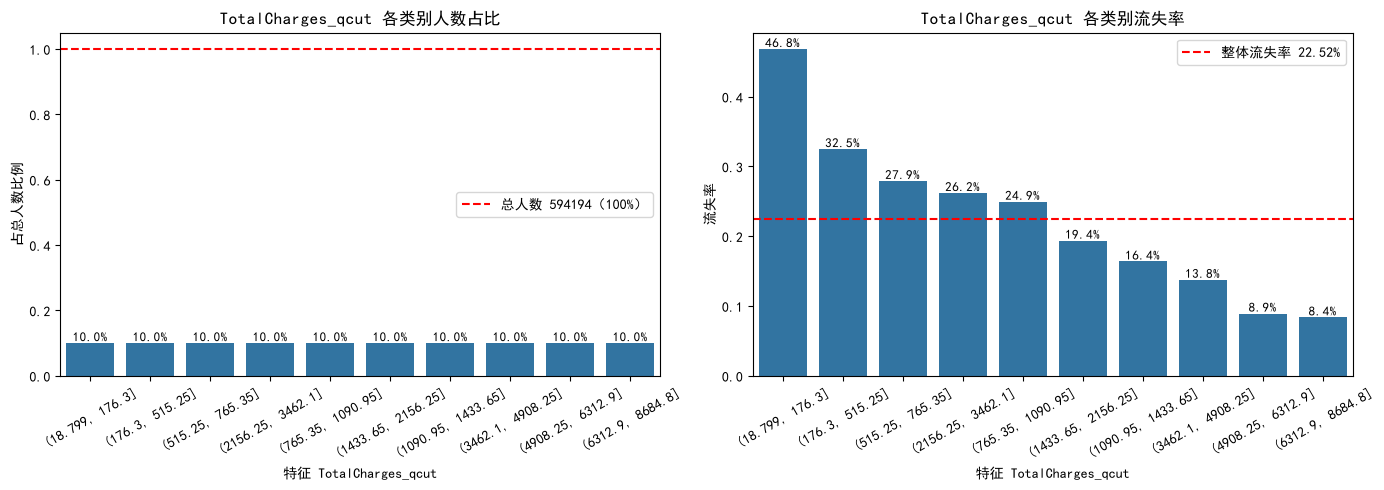

In [16]:
# 分别对特征进行流失率分析
for item in features_in_str:
    res = analyze_churn_by_feature(train, item)

## 单变量分析总结

本次数据集共包含 594194 条客户记录，其中流失客户 133817 人，整体流失率约为 22.52%。

通过对各个特征分别进行客户人数、流失人数及流失率统计，可以得到以下结论：

**1. 用户基本属性方面**

性别对客户流失的影响表现不明显，男女客户流失率分别为 22.80% 和 22.23%，差异较小。

老年客户的流失率达到 50.03%，明显高于非老年客户的 18.98%。虽然老年客户在人群中的占比较低，但其流失比例较高，值得进一步关注。

无伴侣客户的流失率为 32.46%，高于有伴侣客户的 13.38%；无监护人客户的流失率为 29.14%，高于有监护人客户的 7.28%。同时，无监护人客户在人群中占比较大，流失人数也较多。

**2. 电话服务方面**

开通电话服务的客户占据绝大多数，其流失率为 22.89%，与整体流失率接近。未开通电话服务的客户流失率为 16.82%，相对较低，但仍存在一定流失情况。

在开通电话服务的客户中，拥有多条电话线路的客户流失率为 27.70%，高于没有开通多条线路的客户（18.23%）。

**3. 网络服务方面**

网络服务类型之间存在明显的流失率差异。光纤网络客户流失率达到 41.54%，明显高于 DSL 用户的 10.31%，而没有网络服务的客户流失率仅为 1.43%。

此外，未开通 OnlineSecurity、OnlineBackup、DeviceProtection 和 TechSupport 服务的客户，流失率普遍高于开通相应服务的客户。其中，未开通网络安全服务和技术支持服务的客户流失率均超过 40%。

相比之下，StreamingTV 和 StreamingMovies 的开通情况与客户流失率之间的差异较小。

**4. 合同、账单及付款方式方面**

合同类型表现出非常明显的流失率差异。按月合同客户流失率为 42.05%，一年合同客户为 5.76%，两年合同客户仅为 1.00%，说明合同期限与客户流失存在较强的统计关联。

付款方式方面，使用 Electronic check 的客户流失率达到 48.91%，明显高于其他付款方式。使用无纸化账单的客户流失率为 31.94%，也明显高于未使用无纸化账单的客户（7.46%）。

**总体结论：**

从单变量统计结果来看，不同客户特征与流失率之间存在不同程度的关联。其中，合同类型、付款方式、网络服务类型及部分网络附加服务表现出较明显的类别差异；老年客户、无伴侣客户和无监护人客户也表现出较高的流失率。

性别、电话服务以及娱乐服务等特征的单变量关联相对较弱。

这些结果初步揭示了不同客户群体的流失分布特征，但目前仍属于单变量统计分析，尚未考虑多个特征之间的相互关系，不能直接将统计关联解释为因果关系。后续需要进一步开展特征间关联分析和多变量交叉分析，以识别不同客户属性组合下的流失规律。